<a href="https://colab.research.google.com/github/Sharu-052897/deep-learning/blob/main/LSTM%20exp%208.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q tensorflow pandas numpy matplotlib scikit-learn

In [2]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully!
TensorFlow version: 2.21.0


In [3]:
np.random.seed(42)

months = 240

time = np.arange(months)

consumption = (
    200 +
    0.5 * time +
    30 * np.sin(2 * np.pi * time / 12) +
    np.random.normal(0, 5, months)
)

data = pd.DataFrame({
    'Electricity_Consumption': consumption
})

print(data.head())
print("\nDataset shape:", data.shape)

   Electricity_Consumption
0               202.483571
1               214.808678
2               230.219205
3               239.115149
4               226.809995

Dataset shape: (240, 1)


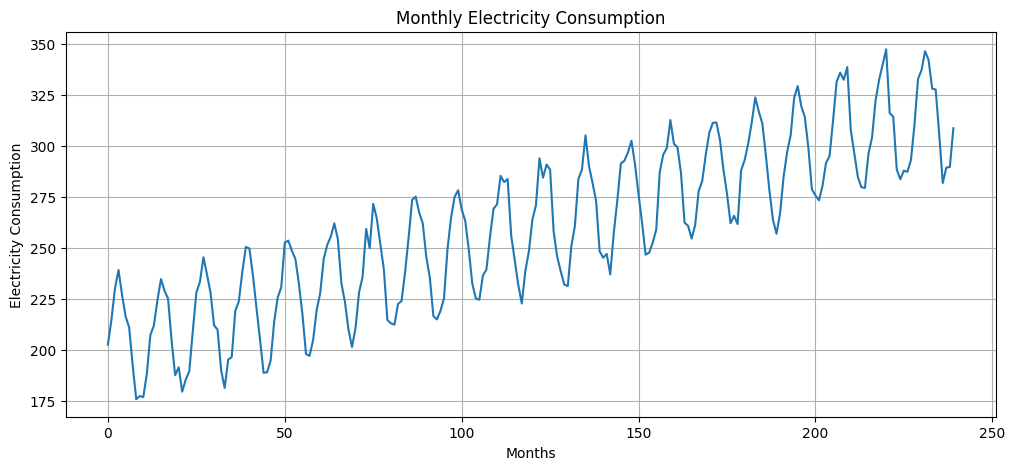

In [4]:
plt.figure(figsize=(12, 5))

plt.plot(data['Electricity_Consumption'])

plt.title("Monthly Electricity Consumption")
plt.xlabel("Months")
plt.ylabel("Electricity Consumption")
plt.grid()

plt.show()

In [5]:
scaler = MinMaxScaler()

split = int(len(data) * 0.8)

scaler.fit(data.iloc[:split])

scaled_data = scaler.transform(data)

print("Data normalization completed!")
print("Training samples:", split)
print("Testing samples:", len(data) - split)

Data normalization completed!
Training samples: 192
Testing samples: 48


In [6]:
LOOKBACK = 12

def create_sequences(dataset, lookback):

    X = []
    y = []

    for i in range(len(dataset) - lookback):

        X.append(dataset[i:i + lookback])
        y.append(dataset[i + lookback, 0])

    return np.array(X), np.array(y)


X_train, y_train = create_sequences(
    scaled_data[:split], LOOKBACK
)

X_test, y_test = create_sequences(
    scaled_data[split - LOOKBACK:], LOOKBACK
)

print("Sequences created successfully!")

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

Sequences created successfully!
X_train shape: (180, 12, 1)
y_train shape: (180,)
X_test shape: (48, 12, 1)
y_test shape: (48,)


In [7]:
lstm_model = Sequential([
    tf.keras.Input(shape=(12, 1)),

    LSTM(64, activation='tanh'),

    Dropout(0.2),

    Dense(32, activation='relu'),

    Dense(1)
])

lstm_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

lstm_model.summary()

print("LSTM model created successfully!")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

LSTM model created successfully!


In [8]:
lstm_history = lstm_model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=16,
    verbose=1
)

Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - loss: 0.1458 - mae: 0.3300 - val_loss: 0.1120 - val_mae: 0.3042
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0378 - mae: 0.1579 - val_loss: 0.0314 - val_mae: 0.1408
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0327 - mae: 0.1508 - val_loss: 0.0461 - val_mae: 0.1772
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0272 - mae: 0.1396 - val_loss: 0.0354 - val_mae: 0.1603
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0247 - mae: 0.1345 - val_loss: 0.0232 - val_mae: 0.1362
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0275 - mae: 0.1398 - val_loss: 0.0301 - val_mae: 0.1507
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0264 - mae: 0.1382 - val_loss: 0.0249 - val_mae: 0.1405
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0254 - mae: 0.1370 - val_loss: 0.0254 - val_mae: 0.1414
Epoch 9/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0243 - mae: 0.1349 - 

In [9]:
predictions = lstm_model.predict(X_test)

actual_values = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

predicted_values = scaler.inverse_transform(
    predictions
)

print("Actual values:", actual_values[:5].flatten())
print("Predicted values:", predicted_values[:5].flatten())

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
Actual values: [297.07046872 305.27130611 323.84666674 329.4265869  319.56147493]
Predicted values: [294.10422 299.33057 302.75427 306.45758 306.37732]


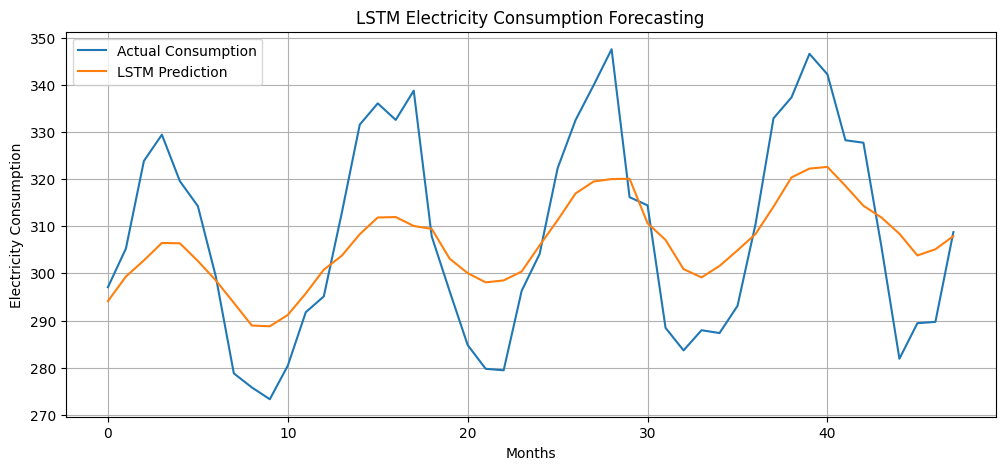

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(actual_values, label='Actual Consumption')
plt.plot(predicted_values, label='LSTM Prediction')

plt.title("LSTM Electricity Consumption Forecasting")
plt.xlabel("Months")
plt.ylabel("Electricity Consumption")

plt.legend()
plt.grid()
plt.show()

In [11]:
loss, mae = lstm_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", round(loss, 4))
print("Test MAE:", round(mae, 4))

Test Loss: 0.0108
Test MAE: 0.0898


In [12]:
np.random.seed(42)

SAMPLES = 1000
TIME_STEPS = 256

X_audio = []
y_audio = []

for i in range(SAMPLES):

    if i < SAMPLES // 2:
        frequency = 5
        label = 0
    else:
        frequency = 12
        label = 1

    t = np.linspace(0, 1, TIME_STEPS)

    phase = np.random.uniform(0, 2 * np.pi)

    signal = np.sin(
        2 * np.pi * frequency * t + phase
    )

    noise = np.random.normal(0, 0.1, TIME_STEPS)

    audio = signal + noise

    X_audio.append(audio)
    y_audio.append(label)


X_audio = np.array(X_audio)
y_audio = np.array(y_audio)

X_audio = X_audio.reshape(SAMPLES, TIME_STEPS, 1)

print("Audio dataset generated successfully!")
print("Audio shape:", X_audio.shape)
print("Labels shape:", y_audio.shape)

Audio dataset generated successfully!
Audio shape: (1000, 256, 1)
Labels shape: (1000,)


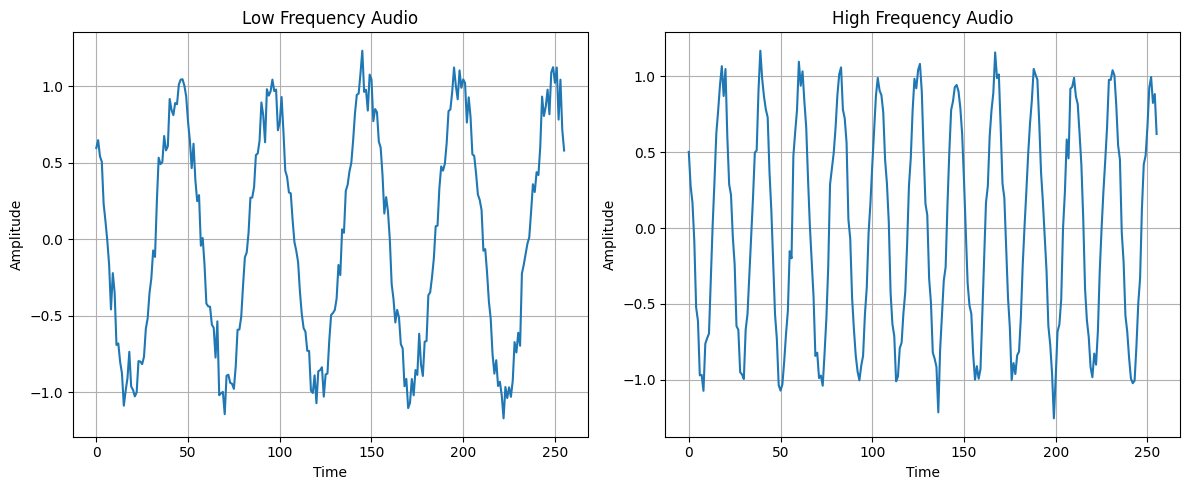

In [13]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(X_audio[0].flatten())

plt.title("Low Frequency Audio")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(X_audio[750].flatten())

plt.title("High Frequency Audio")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.grid()

plt.tight_layout()
plt.show()

In [14]:
from sklearn.model_selection import train_test_split

X_audio_train, X_audio_test, y_audio_train, y_audio_test = train_test_split(
    X_audio,
    y_audio,
    test_size=0.2,
    random_state=42,
    stratify=y_audio
)

print("Audio dataset split completed!")

print("Training shape:", X_audio_train.shape)
print("Testing shape:", X_audio_test.shape)

Audio dataset split completed!
Training shape: (800, 256, 1)
Testing shape: (200, 256, 1)


In [15]:
audio_model = Sequential([
    tf.keras.Input(shape=(256, 1)),

    LSTM(64, activation='tanh'),

    Dropout(0.3),

    Dense(32, activation='relu'),

    Dense(1, activation='sigmoid')
])

audio_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

audio_model.summary()

print("Audio LSTM model created successfully!")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

Audio LSTM model created successfully!


In [16]:
audio_history = audio_model.fit(
    X_audio_train,
    y_audio_train,
    validation_split=0.2,
    epochs=10,
    batch_size=32,
    verbose=1
)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.5859 - loss: 0.6703 - val_accuracy: 0.5938 - val_loss: 0.6239
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7031 - loss: 0.5112 - val_accuracy: 0.8375 - val_loss: 0.3993
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9703 - loss: 0.2654 - val_accuracy: 1.0000 - val_loss: 0.0899
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7672 - loss: 0.7990 - val_accuracy: 0.4812 - val_loss: 1.4322
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5094 - loss: 0.9539 - val_accuracy: 0.5938 - val_loss: 0.7156
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6625 - loss: 0.5998 - val_accuracy: 0.6375 - val_loss: 0.5882
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7328 - loss: 0.5589 - val_accuracy: 0.7563 - val_loss: 0.5259
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7594 - loss: 0.5043 - val_accuracy: 0.8000 - v

In [17]:
audio_loss, audio_accuracy = audio_model.evaluate(
    X_audio_test,
    y_audio_test,
    verbose=0
)

print("Audio Test Loss:", round(audio_loss, 4))

print(
    "Audio Test Accuracy:",
    round(audio_accuracy * 100, 2),
    "%"
)

Audio Test Loss: 0.3611
Audio Test Accuracy: 86.0 %


In [18]:
audio_predictions = audio_model.predict(
    X_audio_test,
    verbose=0
)

predicted_classes = (
    audio_predictions > 0.5
).astype(int)

print("Actual classes:", y_audio_test[:10])
print("Predicted classes:", predicted_classes[:10].flatten())

Actual classes: [1 0 0 0 1 1 1 1 0 0]
Predicted classes: [1 0 0 0 0 1 1 0 0 0]


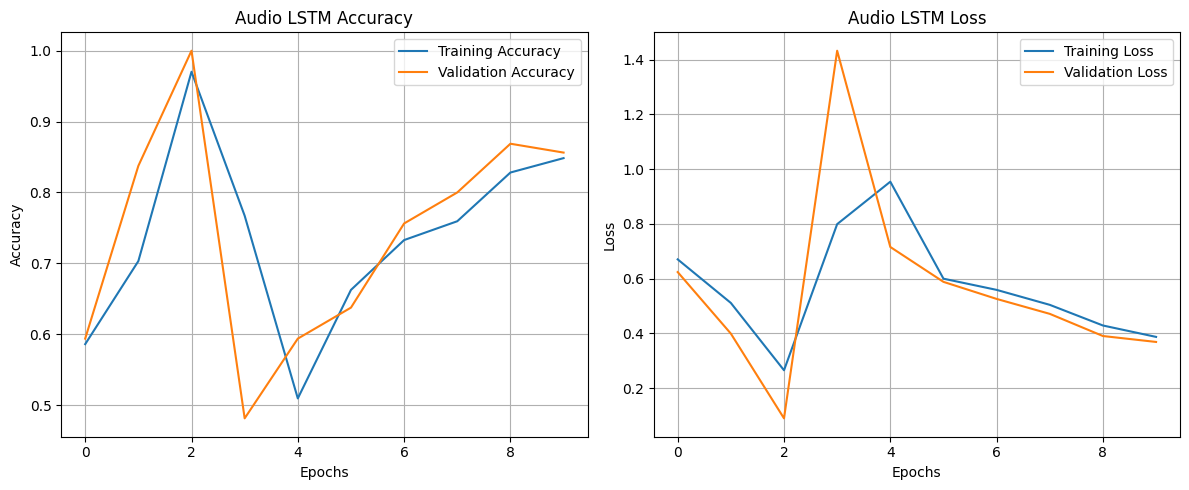

In [19]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(audio_history.history['accuracy'], label='Training Accuracy')
plt.plot(audio_history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Audio LSTM Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(audio_history.history['loss'], label='Training Loss')
plt.plot(audio_history.history['val_loss'], label='Validation Loss')

plt.title("Audio LSTM Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()